In [ ]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn xgboost shap joblib streamlit

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving archive.zip to archive (2).zip


In [ ]:
import os

for root, dirs, files in os.walk('/content'):
    for file in files:
        if file.endswith('.csv'):
            print(os.path.join(root, file))

/content/churn_data/WA_Fn-UseC_-Telco-Customer-Churn.csv
/content/sample_data/mnist_test.csv
/content/sample_data/california_housing_train.csv
/content/sample_data/california_housing_test.csv
/content/sample_data/mnist_train_small.csv


In [ ]:
import zipfile
import os
import glob

# Find uploaded ZIP files
zip_files = glob.glob("/content/*.zip")

print("ZIP files found:", zip_files)

# Extract ZIP
if zip_files:
    zip_path = zip_files[0]

    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall("/content/churn_data")

    print("ZIP extracted successfully!")

else:
    print("No ZIP file found. Please upload again.")

ZIP files found: ['/content/archive.zip', '/content/archive (1).zip', '/content/archive (2).zip']
ZIP extracted successfully!


In [ ]:
csv_files = glob.glob(
    "/content/churn_data/**/*.csv",
    recursive=True
)

print("CSV files found:", csv_files)

CSV files found: ['/content/churn_data/WA_Fn-UseC_-Telco-Customer-Churn.csv']


In [ ]:
import pandas as pd

if csv_files:
    df = pd.read_csv(csv_files[0])
    print("Dataset loaded successfully!")
    print("Shape:", df.shape)
    display(df.head())
else:
    print("No CSV found inside the ZIP file.")

Dataset loaded successfully!
Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
# Remove duplicate rows
df = df.drop_duplicates().copy()

# Remove identifier: it should not be used as a predictive feature
if "customerID" in df.columns:
    df = df.drop(columns=["customerID"])

# In the common IBM Telco dataset, TotalCharges may contain blank strings
if "TotalCharges" in df.columns:
    df["TotalCharges"] = pd.to_numeric(
        df["TotalCharges"], errors="coerce"
    )

# Remove rows where the target is missing
df = df.dropna(subset=["Churn"]).copy()

# Convert target into binary values
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

print("Cleaned shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum().sort_values(ascending=False).head(10))

print("\nChurn distribution:")
print(df["Churn"].value_counts())
print("\nChurn percentage:")
print((df["Churn"].value_counts(normalize=True) * 100).round(2))

Cleaned shape: (7043, 20)

Missing values:
TotalCharges      11
gender             0
Partner            0
SeniorCitizen      0
Dependents         0
tenure             0
MultipleLines      0
PhoneService       0
OnlineSecurity     0
OnlineBackup       0
dtype: int64

Churn distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64

Churn percentage:
Churn
0    73.46
1    26.54
Name: proportion, dtype: float64


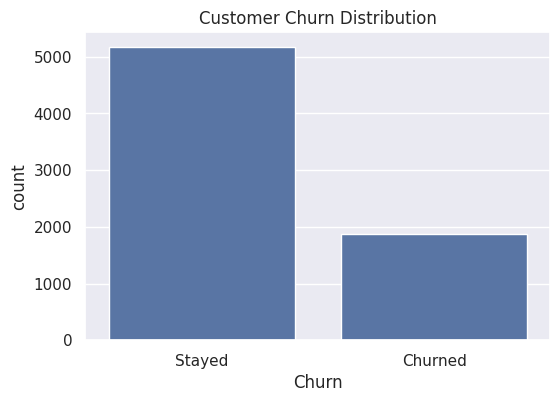

Churn rate: 26.54 %


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xticks([0, 1], ["Stayed", "Churned"])
plt.show()

print("Churn rate:", round(df["Churn"].mean() * 100, 2), "%")

Churn percentage by contract type:


Churn,0,1
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


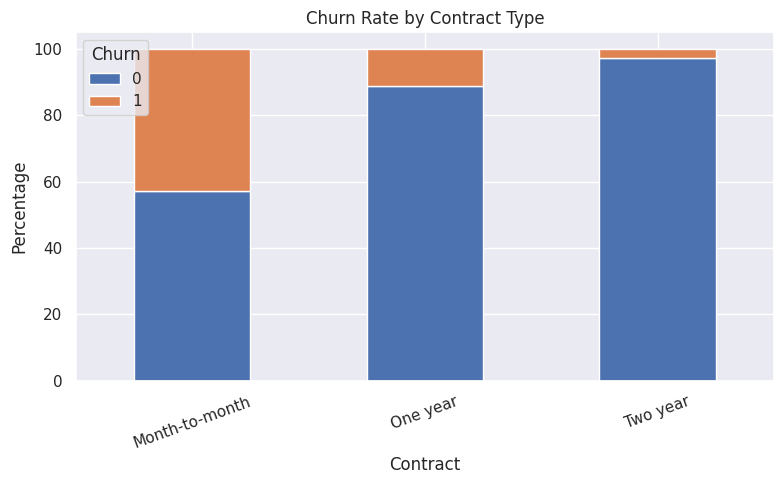

In [ ]:
if "Contract" in df.columns:
    contract_churn = pd.crosstab(
        df["Contract"],
        df["Churn"],
        normalize="index"
    ) * 100

    print("Churn percentage by contract type:")
    display(contract_churn.round(2))

    contract_churn.plot(
        kind="bar",
        stacked=True,
        figsize=(8, 5)
    )
    plt.title("Churn Rate by Contract Type")
    plt.ylabel("Percentage")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

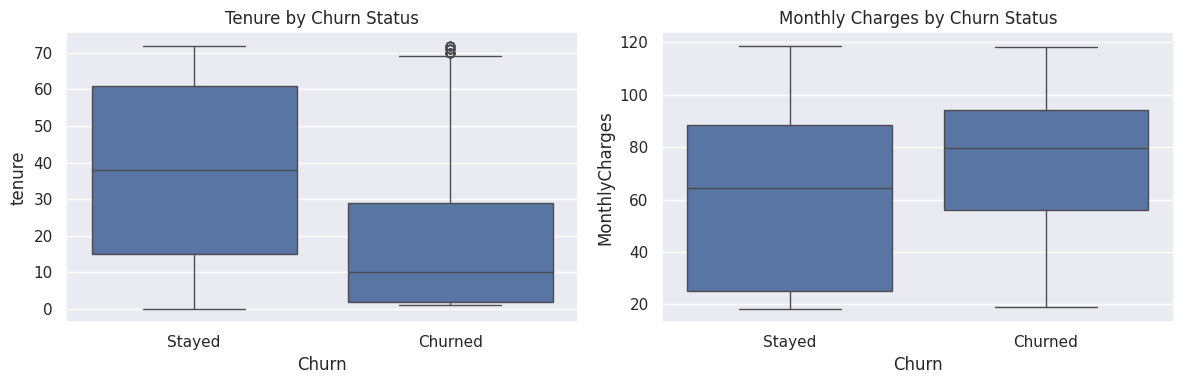

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(data=df, x="Churn", y="tenure", ax=axes[0])
axes[0].set_title("Tenure by Churn Status")
axes[0].set_xticks([0, 1], ["Stayed", "Churned"])

sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=axes[1])
axes[1].set_title("Monthly Charges by Churn Status")
axes[1].set_xticks([0, 1], ["Stayed", "Churned"])

plt.tight_layout()
plt.show()

In [ ]:


# Convert Churn values from text to numbers
df["Churn"] = df["Churn"].astype(str).str.strip().map({
    "No": 0,
    "Yes": 1
})

# Remove rows with missing Churn values, if any
df = df.dropna(subset=["Churn"]).copy()

# Convert Churn to integer
df["Churn"] = df["Churn"].astype(int)

print("Churn column fixed!")
print(df["Churn"].value_counts())
print("\nData types:")
print(df["Churn"].dtype)



Churn column fixed!
Series([], Name: count, dtype: int64)

Data types:
int64


In [ ]:

import pandas as pd
from sklearn.model_selection import train_test_split

# Step 1: Reload original dataset
df = pd.read_csv(
    "/content/churn_data/WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

# Step 2: Clean dataset
df.columns = df.columns.str.strip()
df = df.drop(columns=["customerID"], errors="ignore")

# Step 3: Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

# Step 4: Encode target variable
df["Churn"] = df["Churn"].astype(str).str.strip().map({
    "No": 0,
    "Yes": 1
})

# Step 5: Check dataset
print("Dataset shape:", df.shape)
print("Churn distribution:")
print(df["Churn"].value_counts())

# Step 6: Stop if dataset is empty or invalid
if df.empty or df["Churn"].isna().any():
    raise ValueError("Dataset is empty or Churn values are invalid. Check the CSV file.")

# Step 7: Separate input and output
X = df.drop(columns=["Churn"])
y = df["Churn"].astype(int)

# Step 8: Identify feature types
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

# Step 9: Train-test split (80:20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Step 10: Display results
print("\nTrain-test split successful!")
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)


Dataset shape: (7043, 20)
Churn distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64

Train-test split successful!
Training rows: 5634
Testing rows: 1409
Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

print("All preprocessing libraries imported successfully!")

All preprocessing libraries imported successfully!


In [ ]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )
}

trained_models = {}
results = []

for name, estimator in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]

    from sklearn.metrics import (
        accuracy_score, precision_score, recall_score,
        f1_score, roc_auc_score
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

    trained_models[name] = pipeline

results_df = pd.DataFrame(results).sort_values(
    "F1 Score", ascending=False
)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7381,0.5043,0.7834,0.6136,0.8413
2,XGBoost,0.7984,0.6510,0.5187,0.5774,0.8410
1,Random Forest,0.7814,0.6170,0.4652,0.5305,0.8217


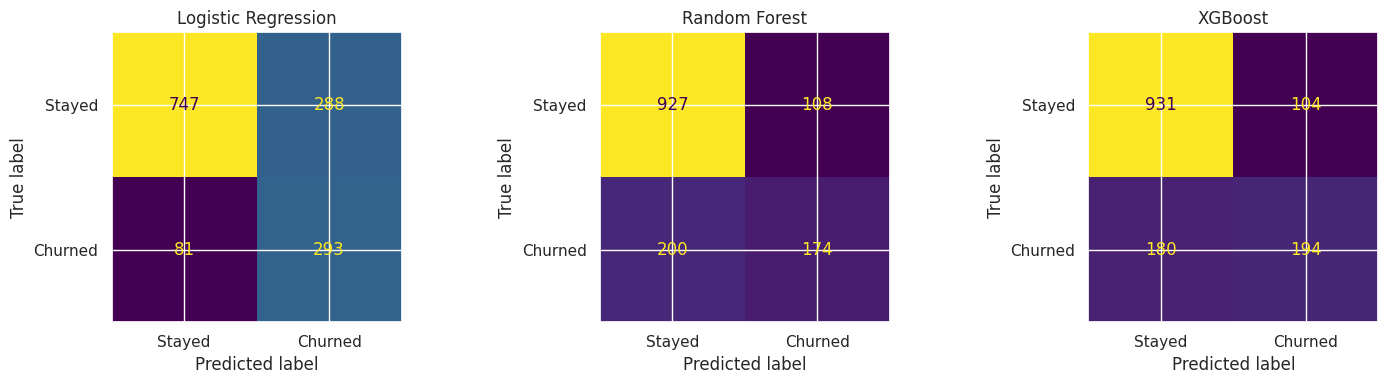

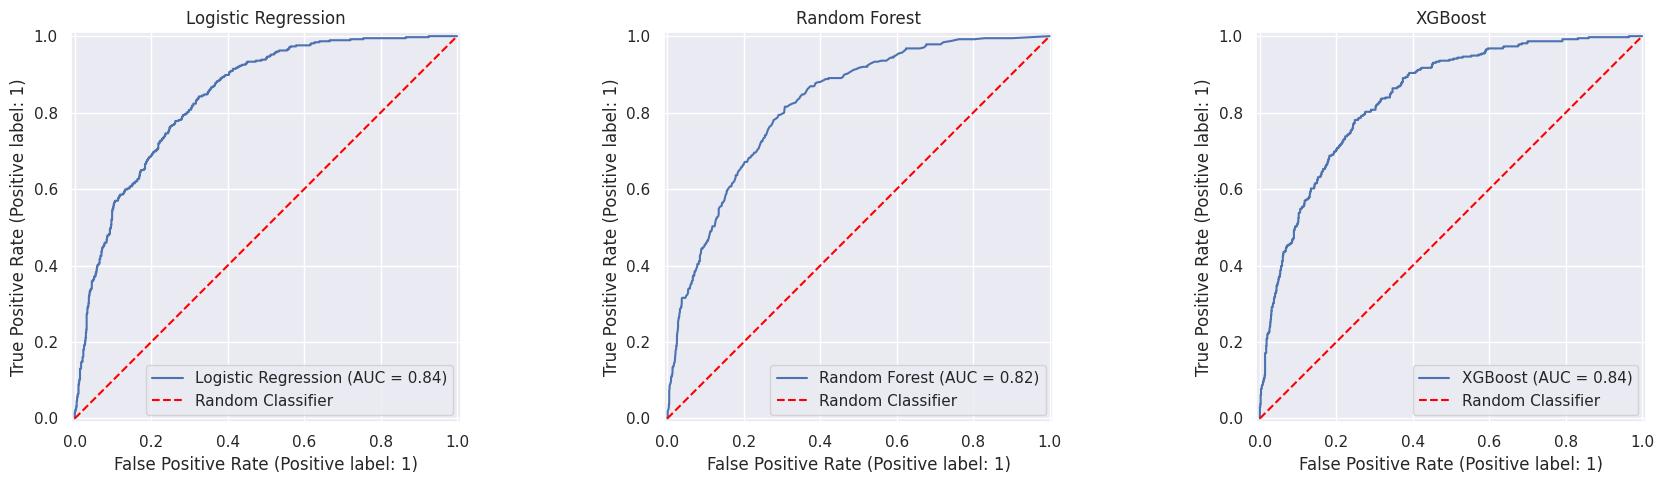

Best model by test F1-score: Logistic Regression
              precision    recall  f1-score   support

      Stayed       0.90      0.72      0.80      1035
     Churned       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



In [ ]:

from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

# 1. Confusion matrices for all three models
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, pipeline) in zip(axes, trained_models.items()):
    ConfusionMatrixDisplay.from_estimator(
        pipeline, X_test, y_test,
        display_labels=["Stayed", "Churned"],
        ax=ax,
        colorbar=False
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()


# 2. ROC curves for all three models
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, pipeline) in zip(axes, trained_models.items()):

    RocCurveDisplay.from_estimator(
        pipeline, X_test, y_test,
        name=name,
        ax=ax
    )

    # Red diagonal reference line
    ax.plot(
        [0, 1], [0, 1],
        color="red",
        linestyle="--",
        label="Random Classifier"
    )

    ax.set_title(name)
    ax.legend()

plt.tight_layout()
plt.show()


# 3. Select the best model based on F1 Score
best_name = results_df.iloc[0]["Model"]
best_pipeline = trained_models[best_name]

print("Best model by test F1-score:", best_name)

# 4. Classification report
print(
    classification_report(
        y_test,
        best_pipeline.predict(X_test),
        target_names=["Stayed", "Churned"],
        zero_division=0
    )
)


Calculating SHAP explanations...
SHAP calculation complete!


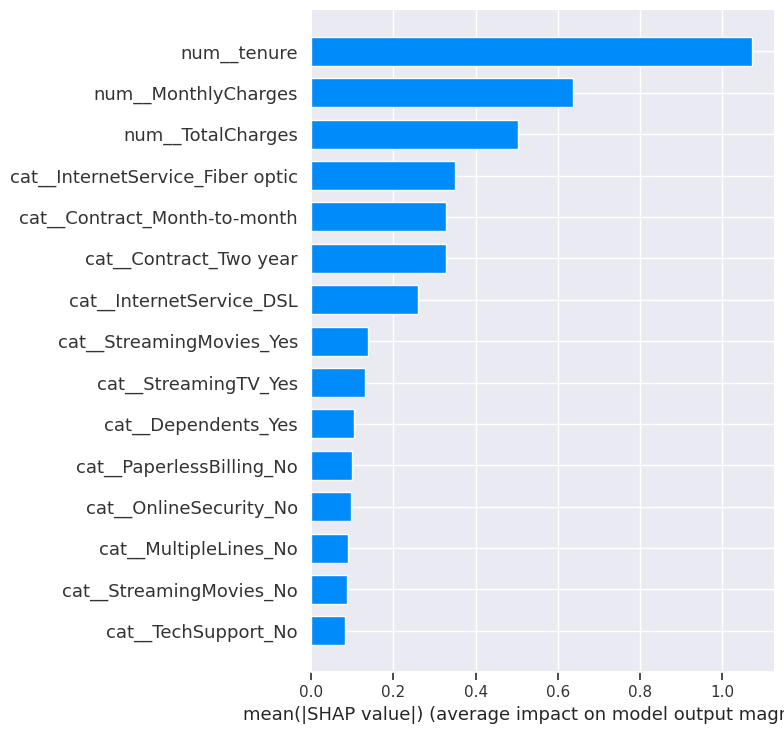

In [ ]:

import shap
import numpy as np
import matplotlib.pyplot as plt

# Select the Logistic Regression model
best_model = trained_models["Logistic Regression"]

# Get the trained model and preprocessor
logistic_model = best_model.named_steps["model"]
preprocessor = best_model.named_steps["preprocessor"]

# Select 20 test customers
X_shap = preprocessor.transform(X_test.iloc[:20])

# Convert sparse data to a normal array
if hasattr(X_shap, "toarray"):
    X_shap = X_shap.toarray()

X_shap = np.asarray(X_shap, dtype=np.float64)

# Get feature names
feature_names = preprocessor.get_feature_names_out()

print("Calculating SHAP explanations...")

# Create SHAP explainer for Logistic Regression
explainer = shap.LinearExplainer(logistic_model, X_shap)
shap_values = explainer(X_shap)

print("SHAP calculation complete!")

# Display feature importance
shap.summary_plot(
    shap_values.values,
    X_shap,
    feature_names=feature_names,
    plot_type="bar",
    max_display=15
)


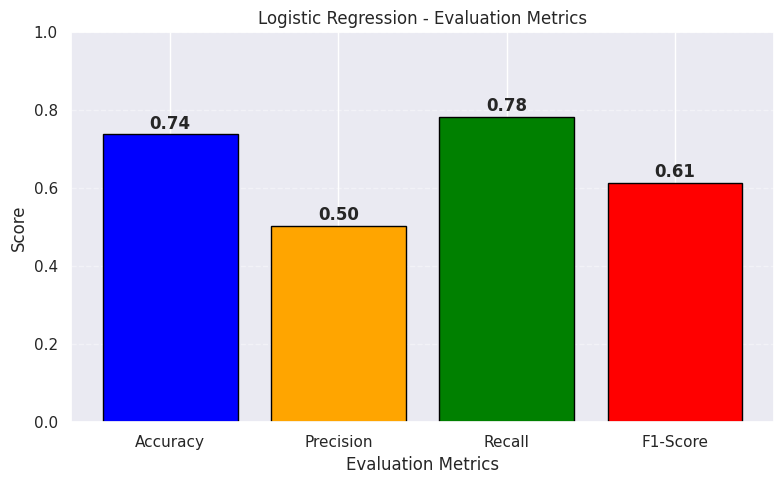

Logistic Regression Metrics:
Accuracy: 0.74
Precision: 0.50
Recall: 0.78
F1-Score: 0.61


In [ ]:

import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Select Logistic Regression model
logistic_model = trained_models["Logistic Regression"]

# Predict test data
y_pred = logistic_model.predict(X_test)

# Calculate actual evaluation metrics
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

scores = [
    accuracy_score(y_test, y_pred),
    precision_score(y_test, y_pred, pos_label=1, zero_division=0),
    recall_score(y_test, y_pred, pos_label=1, zero_division=0),
    f1_score(y_test, y_pred, pos_label=1, zero_division=0)
]

plt.figure(figsize=(8, 5))

bars = plt.bar(
    metrics,
    scores,
    color=["blue", "orange", "green", "red"],
    edgecolor="black"
)

# Show values above bars
for bar, score in zip(bars, scores):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.015,
        f"{score:.2f}",
        ha="center",
        fontsize=12,
        fontweight="bold"
    )

plt.title("Logistic Regression - Evaluation Metrics")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.ylim(0, 1.0)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()

# Save the chart
plt.savefig("logistic_regression_metrics.png", dpi=300)
plt.show()

print("Logistic Regression Metrics:")
for metric, score in zip(metrics, scores):
    print(f"{metric}: {score:.2f}")


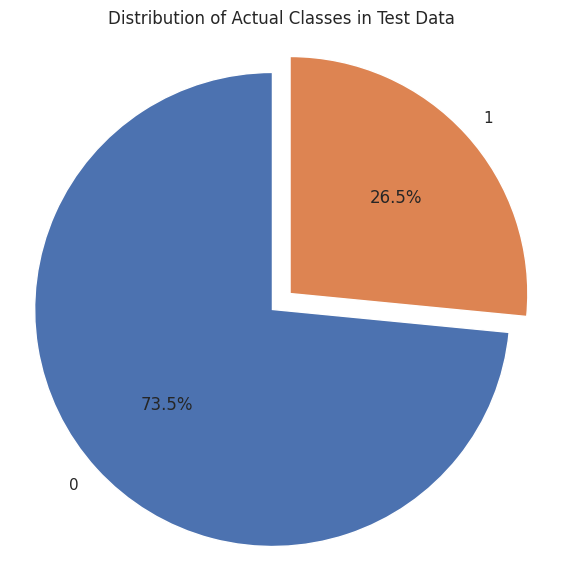

In [ ]:
import matplotlib.pyplot as plt

# Count actual classes in the test dataset
class_counts = pd.Series(y_test).value_counts()

# Create pie chart
plt.figure(figsize=(7, 7))

plt.pie(
    class_counts,
    labels=class_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    explode=[0.05] * len(class_counts)
)

plt.title("Distribution of Actual Classes in Test Data")
plt.axis("equal")
plt.show()

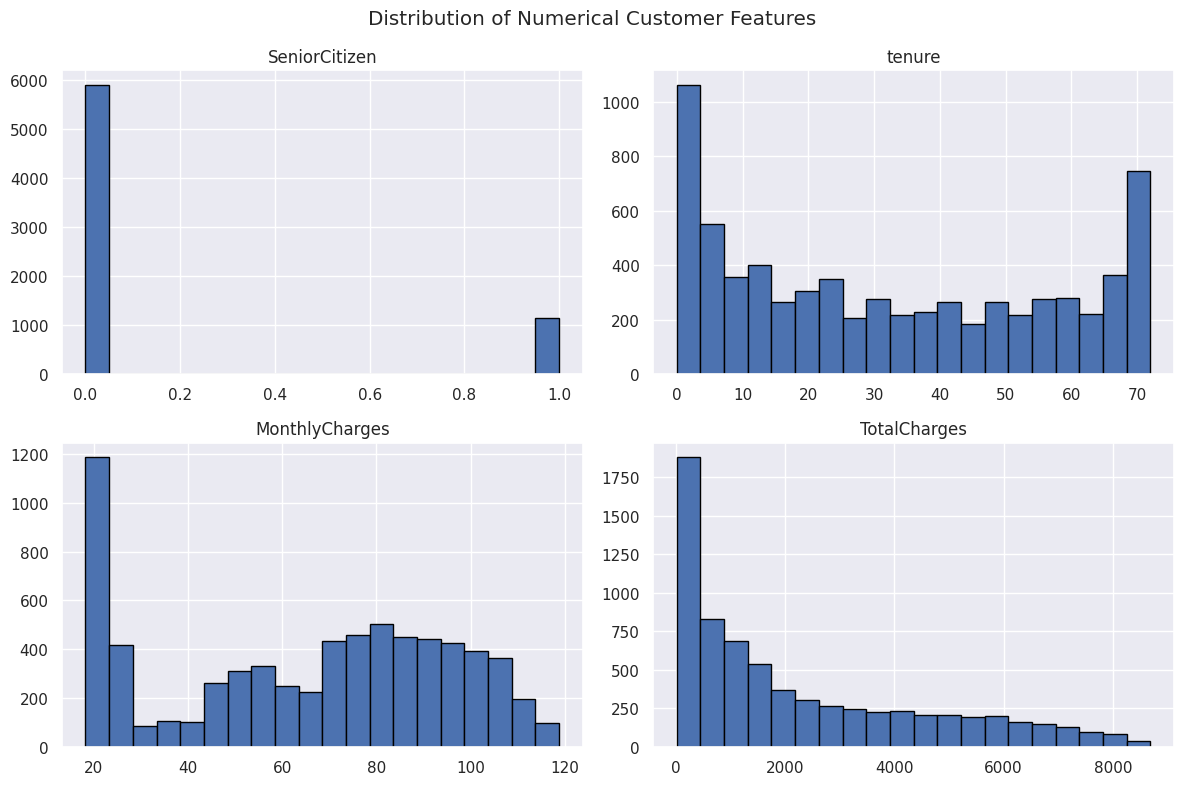

In [ ]:
import matplotlib.pyplot as plt

num_cols = df.select_dtypes(include="number").columns.drop(
    "Churn", errors="ignore"
)

df[num_cols].hist(figsize=(12, 8), bins=20, edgecolor="black")

plt.suptitle("Distribution of Numerical Customer Features")
plt.tight_layout()
plt.show()

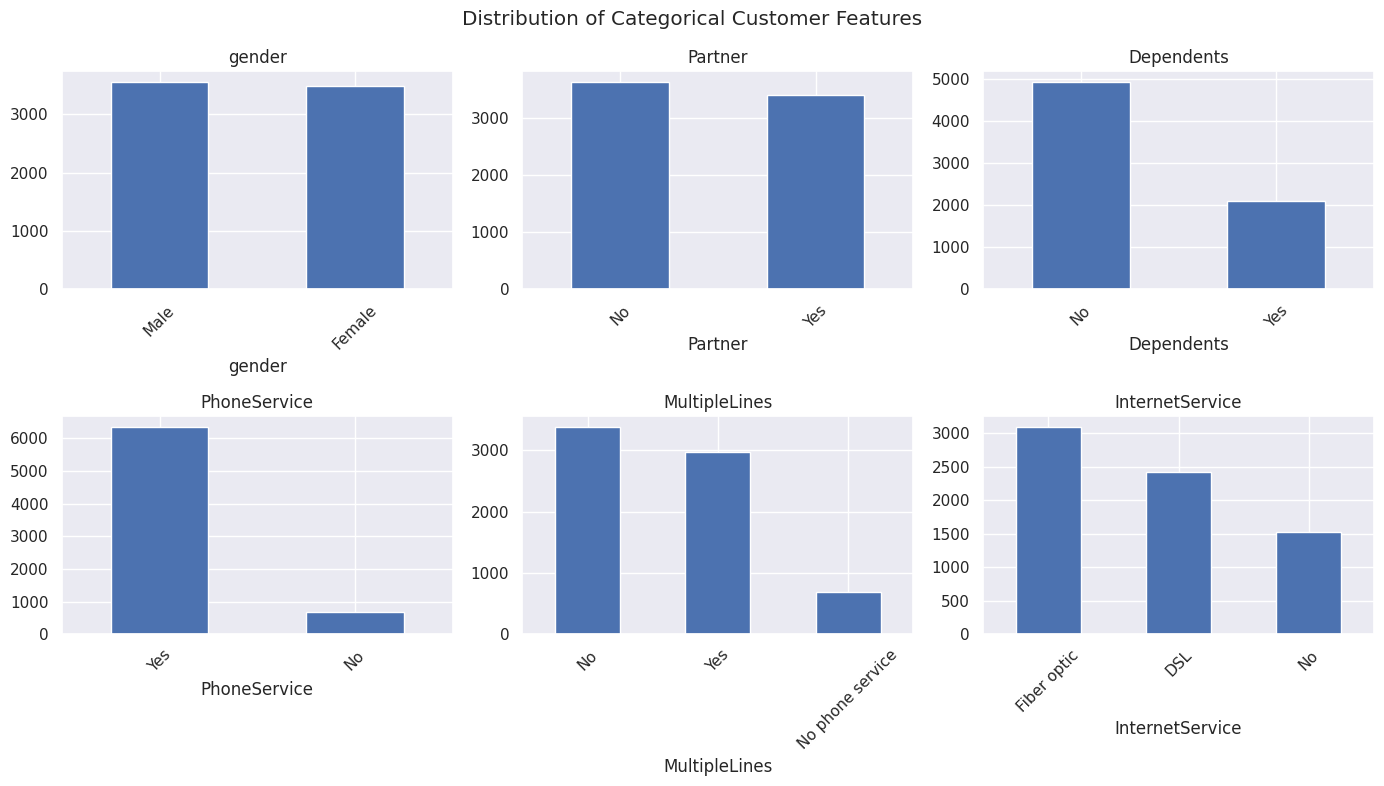

In [ ]:
import matplotlib.pyplot as plt

cat_cols = df.select_dtypes(exclude="number").columns.tolist()
cols = cat_cols[:6]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for col, ax in zip(cols, axes.flat):
    df[col].value_counts().head(8).plot(kind="bar", ax=ax)
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=45)

for ax in axes.flat[len(cols):]:
    ax.set_visible(False)

fig.suptitle("Distribution of Categorical Customer Features")
plt.tight_layout()
plt.show()

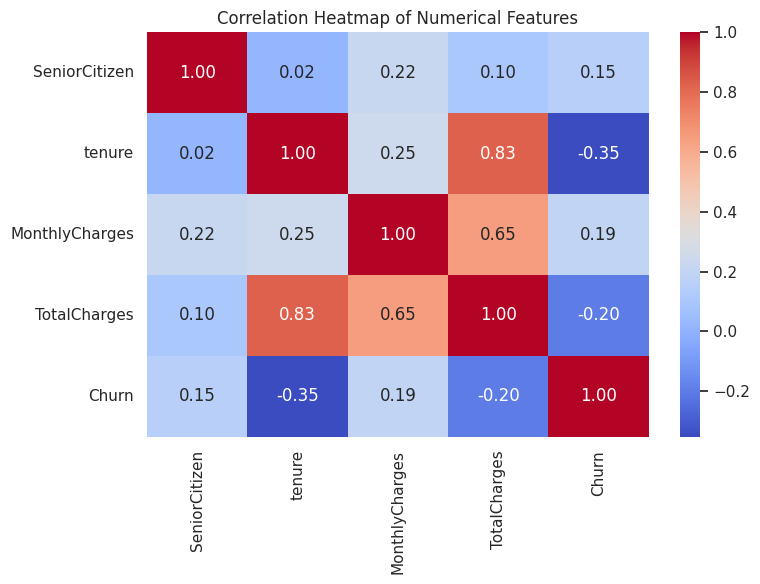

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

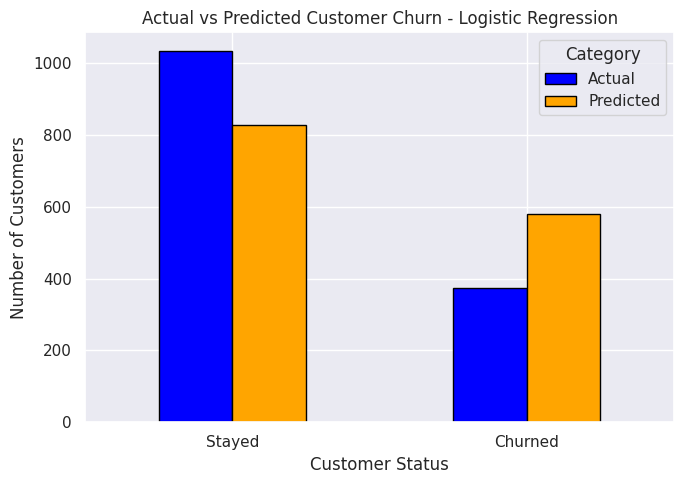

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Get trained Logistic Regression model
logistic_model = trained_models["Logistic Regression"]

# Generate predictions
pred = logistic_model.predict(X_test)

# Count actual and predicted customers
actual = pd.Series(y_test).value_counts().reindex([0, 1], fill_value=0)
predicted = pd.Series(pred).value_counts().reindex([0, 1], fill_value=0)

# Create comparison dataframe
plot_df = pd.DataFrame({
    "Actual": actual.values,
    "Predicted": predicted.values
}, index=["Stayed", "Churned"])

# Plot graph
plot_df.plot(
    kind="bar",
    figsize=(7, 5),
    color=["blue", "orange"],
    edgecolor="black"
)

plt.title("Actual vs Predicted Customer Churn - Logistic Regression")
plt.xlabel("Customer Status")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.legend(title="Category")
plt.tight_layout()
plt.show()


In [ ]:
print("Available trained models:", trained_models.keys())
print("\nAvailable model names:", models.keys())

Available trained models: dict_keys(['Logistic Regression', 'Random Forest', 'XGBoost'])

Available model names: dict_keys(['Logistic Regression', 'Random Forest', 'XGBoost'])


In [ ]:
import joblib

# Save Logistic Regression model
logistic_pipeline = trained_models["Logistic Regression"]

model_bundle = {
    "model": logistic_pipeline,
    "features": X_train.columns.tolist()
}

joblib.dump(model_bundle, "/content/churn_model_bundle.joblib")

print("Logistic Regression model saved successfully!")

Logistic Regression model saved successfully!


In [ ]:
from google.colab import files

files.download("/content/churn_model_bundle.joblib")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>